# A7: Hierarchical Clustering and PCA on AIMO

This notebook covers the Lab 7 machine learning tasks for the AIMO observations:
- perform a clustering of the AIMO observations while excluding score columns
- interpret the clusters
- perform a PCA of the AIMO observations
- draw the first two principal component scores in a colored 2D scatterplot
- interpret the PCA plot

The workflow below uses **hierarchical clustering with Ward linkage** and then projects the same scaled feature space onto the first two principal components.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

In [2]:
def locate_data_file() -> Path:
    relative_path = Path("ml/models/data/processed/20190108_scores_and_weak_links.csv")
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / relative_path
        if candidate.exists():
            return candidate

    fallback = (Path.cwd() / "../../data/processed/20190108_scores_and_weak_links.csv").resolve()
    if fallback.exists():
        return fallback

    raise FileNotFoundError("Could not locate 20190108_scores_and_weak_links.csv from the current notebook location.")


DATA_PATH = locate_data_file()
df = pd.read_csv(DATA_PATH)

print(f"Loaded data from: {DATA_PATH}")
print(f"Shape: {df.shape}")
df.head()

Loaded data from: c:\Users\kimwo\software engineering\year 4\LP3\4DT907 - Project\machine_learning_project_4dt907\ml\models\data\processed\20190108_scores_and_weak_links.csv
Shape: (2096, 17)


,ID,Date,SCORE,ForwardHead,LeftArmFallForward,RightArmFallForward,LeftShoulderElevation,RightShoulderElevation,ExcessiveForwardLean,LeftAsymmetricalWeightShift,RightAsymmetricalWeightShift,LeftKneeMovesInward,RightKneeMovesInward,LeftKneeMovesOutward,RightKneeMovesOutward,LeftHeelRises,RightHeelRises
0,cf0e95ab-d6ec-475a-9cc0-c9444b8dd080.Kinect,2018-07-19,0.612532,0.31,1.34,1.15,0.33,0.49,0.00,0.0,0.08,0.00,0.00,0.00,0.77,0.00,0.0
1,6210cc6d-575d-4e9f-bab1-4fe1da2a30a3.Kinect,2018-07-30,0.388809,1.49,1.42,1.39,0.00,0.00,1.08,0.1,0.00,0.00,0.00,0.00,0.40,0.00,0.0
2,2fc2eaad-c098-4b91-94c8-40241da1908e.Kinect,2018-06-19,0.205311,0.01,1.02,1.50,1.07,0.61,0.00,1.5,0.00,0.00,0.95,1.18,0.00,0.00,0.0
3,60ccb803-a949-403b-80d0-80f8aa36c60d.Kinect,2018-08-25,0.073400,0.00,1.01,0.01,0.02,0.00,0.00,0.0,0.00,0.00,0.00,1.36,1.50,0.21,1.3
4,90a7047d-452c-4889-b985-3f99afbb9ec0.Kinect,2018-05-09,0.728731,0.00,0.00,0.00,1.35,1.31,0.05,0.0,0.00,0.08,0.62,0.00,0.00,0.00,0.0


In [3]:
# Exclude identifiers, dates, and any column that contains the word 'score'.
meta_cols = [col for col in ["ID", "Date"] if col in df.columns]
score_cols = [col for col in df.columns if "score" in col.lower()]
excluded_cols = meta_cols + [col for col in score_cols if col not in meta_cols]
feature_cols = [col for col in df.columns if col not in excluded_cols]

X = df[feature_cols].copy()

print("Excluded columns:", excluded_cols)
print("Feature columns used for clustering and PCA:")
print(feature_cols)
print(f"Number of observations: {len(X)}")
print(f"Number of features: {X.shape[1]}")

X.describe().T

Excluded columns: ['ID', 'Date', 'SCORE']
Feature columns used for clustering and PCA:
['ForwardHead', 'LeftArmFallForward', 'RightArmFallForward', 'LeftShoulderElevation', 'RightShoulderElevation', 'ExcessiveForwardLean', 'LeftAsymmetricalWeightShift', 'RightAsymmetricalWeightShift', 'LeftKneeMovesInward', 'RightKneeMovesInward', 'LeftKneeMovesOutward', 'RightKneeMovesOutward', 'LeftHeelRises', 'RightHeelRises']
Number of observations: 2096
Number of features: 14


,count,mean,std,min,25%,50%,75%,max
ForwardHead,2096.0,0.301579,0.477732,0.0,0.00,0.000,0.4800,1.50
LeftArmFallForward,2096.0,0.996842,0.481902,0.0,0.69,1.120,1.3900,1.50
RightArmFallForward,2096.0,0.880792,0.578039,0.0,0.17,1.110,1.4200,1.50
LeftShoulderElevation,2096.0,0.271293,0.418118,0.0,0.00,0.030,0.3900,1.50
RightShoulderElevation,2096.0,0.465000,0.475603,0.0,0.03,0.325,0.8525,1.50
ExcessiveForwardLean,2096.0,0.201150,0.419338,0.0,0.00,0.000,0.0800,1.50
LeftAsymmetricalWeightShift,2096.0,0.175219,0.397579,0.0,0.00,0.000,0.0500,1.50
RightAsymmetricalWeightShift,2096.0,0.065315,0.252260,0.0,0.00,0.000,0.0000,1.50
LeftKneeMovesInward,2096.0,0.037657,0.140765,0.0,0.00,0.000,0.0000,1.31
RightKneeMovesInward,2096.0,0.179089,0.329131,0.0,0.00,0.000,0.2000,1.50


## Scaling and hierarchical clustering

The variables are standardized before clustering so that features with larger numeric spread do not dominate the distance calculations. The clustering below uses **Ward linkage**, which merges clusters in a way that tries to keep within-cluster variance small.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

linkage_matrix = linkage(X_scaled, method="ward")

print(f"Scaled feature matrix shape: {X_scaled.shape}")

Scaled feature matrix shape: (2096, 14)


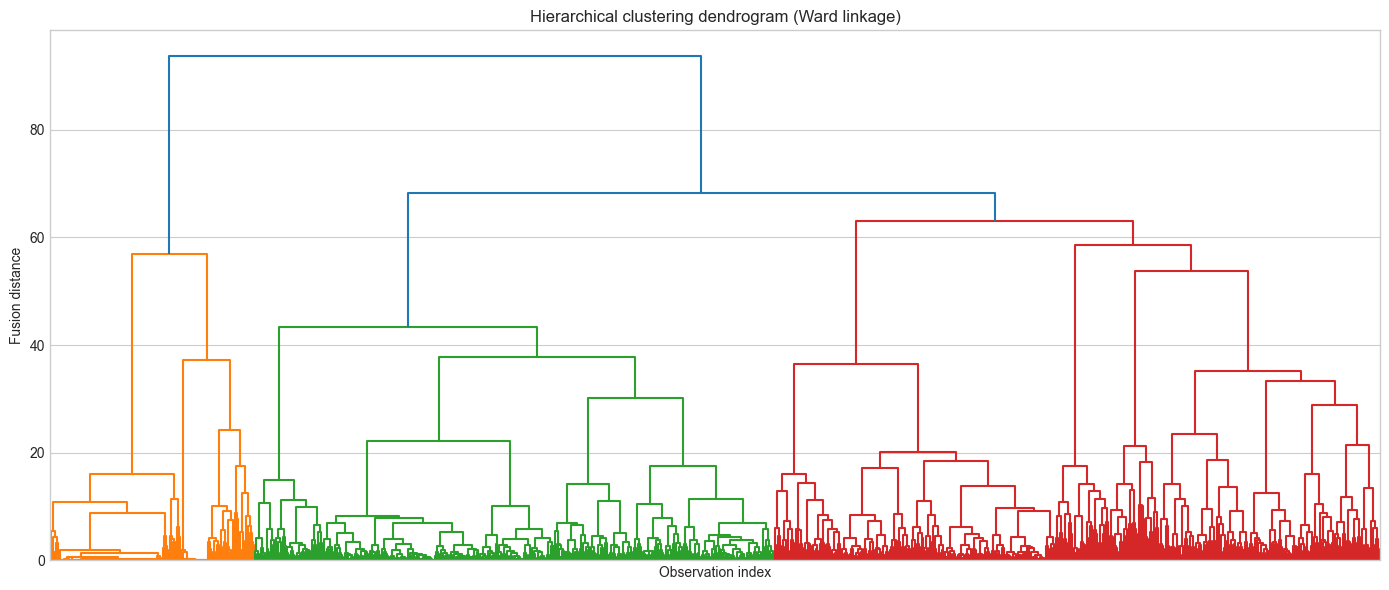

In [5]:
plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, no_labels=True, color_threshold=None)
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.xlabel("Observation index")
plt.ylabel("Fusion distance")
plt.tight_layout()
plt.show()

In [6]:
# Compare a few possible cuts of the dendrogram.
silhouette_rows = []

for k in range(2, 8):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    counts = np.bincount(labels)
    silhouette_rows.append(
        {
            "k": k,
            "silhouette_score": silhouette_score(X_scaled, labels),
            "smallest_cluster": int(counts.min()),
            "largest_cluster": int(counts.max()),
        }
    )

silhouette_df = pd.DataFrame(silhouette_rows).sort_values("silhouette_score", ascending=False).reset_index(drop=True)
silhouette_df

,k,silhouette_score,smallest_cluster,largest_cluster
0,2,0.263416,322,1774
1,7,0.238531,77,820
2,6,0.222778,86,820
3,5,0.193183,86,820
4,4,0.172551,322,820
5,3,0.162897,322,954


In [7]:
# Start with the best silhouette score, then adjust manually if the dendrogram suggests a more meaningful cut.
chosen_k = int(silhouette_df.loc[silhouette_df["silhouette_score"].idxmax(), "k"])
print(f"Automatically selected number of clusters: {chosen_k}")

cluster_model = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
cluster_labels = cluster_model.fit_predict(X_scaled)

clustered_df = df.copy()
clustered_df["cluster"] = cluster_labels.astype(int)

clustered_df["cluster"].value_counts().sort_index().rename("n_observations")

Automatically selected number of clusters: 2


cluster
0    1774
1     322
Name: n_observations, dtype: int64

In [8]:
cluster_mean_table = clustered_df.groupby("cluster")[feature_cols].mean().round(3)
cluster_size_table = clustered_df.groupby("cluster").size().rename("n_observations")

cluster_summary = cluster_size_table.to_frame().join(cluster_mean_table)
cluster_summary

,n_observations,ForwardHead,LeftArmFallForward,RightArmFallForward,LeftShoulderElevation,RightShoulderElevation,ExcessiveForwardLean,LeftAsymmetricalWeightShift,RightAsymmetricalWeightShift,LeftKneeMovesInward,RightKneeMovesInward,LeftKneeMovesOutward,RightKneeMovesOutward,LeftHeelRises,RightHeelRises
cluster,,,,,,,,,,,,,,,
0,1774,0.350,0.984,0.983,0.311,0.484,0.235,0.202,0.076,0.042,0.208,0.142,0.033,0.012,0.008
1,322,0.034,1.067,0.318,0.053,0.361,0.013,0.025,0.008,0.011,0.017,0.331,1.371,0.317,0.625


In [9]:
# Compare each cluster mean to the overall mean in standardized units.
feature_means = X.mean()
feature_stds = X.std(ddof=0).replace(0, np.nan)
cluster_z_scores = (clustered_df.groupby("cluster")[feature_cols].mean() - feature_means) / feature_stds


def top_cluster_traits(cluster_row: pd.Series, top_n: int = 4):
    strongest = cluster_row.abs().sort_values(ascending=False).head(top_n).index
    return [(feature, cluster_row[feature]) for feature in strongest]


for cluster_id, row in cluster_z_scores.iterrows():
    n_obs = int(cluster_size_table.loc[cluster_id])
    print(f"Cluster {cluster_id} (n={n_obs})")
    for feature, value in top_cluster_traits(row):
        direction = "higher" if value > 0 else "lower"
        print(f"  - {feature}: {direction} than the dataset average (z={value:.2f})")
    print()

Cluster 0 (n=1774)
  - RightKneeMovesOutward: lower than the dataset average (z=-0.39)
  - RightHeelRises: lower than the dataset average (z=-0.33)
  - LeftHeelRises: lower than the dataset average (z=-0.21)
  - RightArmFallForward: higher than the dataset average (z=0.18)

Cluster 1 (n=322)
  - RightKneeMovesOutward: higher than the dataset average (z=2.14)
  - RightHeelRises: higher than the dataset average (z=1.80)
  - LeftHeelRises: higher than the dataset average (z=1.14)
  - RightArmFallForward: lower than the dataset average (z=-0.97)



## PCA

PCA is applied to the same scaled observation matrix. This lets us inspect whether the hierarchical clusters are separated along the two directions that explain the most variance in the data.

In [10]:
pca = PCA(n_components=2)
pc_scores = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(pc_scores, columns=["PC1", "PC2"])
pca_df["cluster"] = cluster_labels.astype(int)

explained_variance = pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2"],
    name="explained_variance_ratio",
)

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=["PC1", "PC2"],
)

explained_variance.to_frame()

,explained_variance_ratio
PC1,0.216764
PC2,0.147666


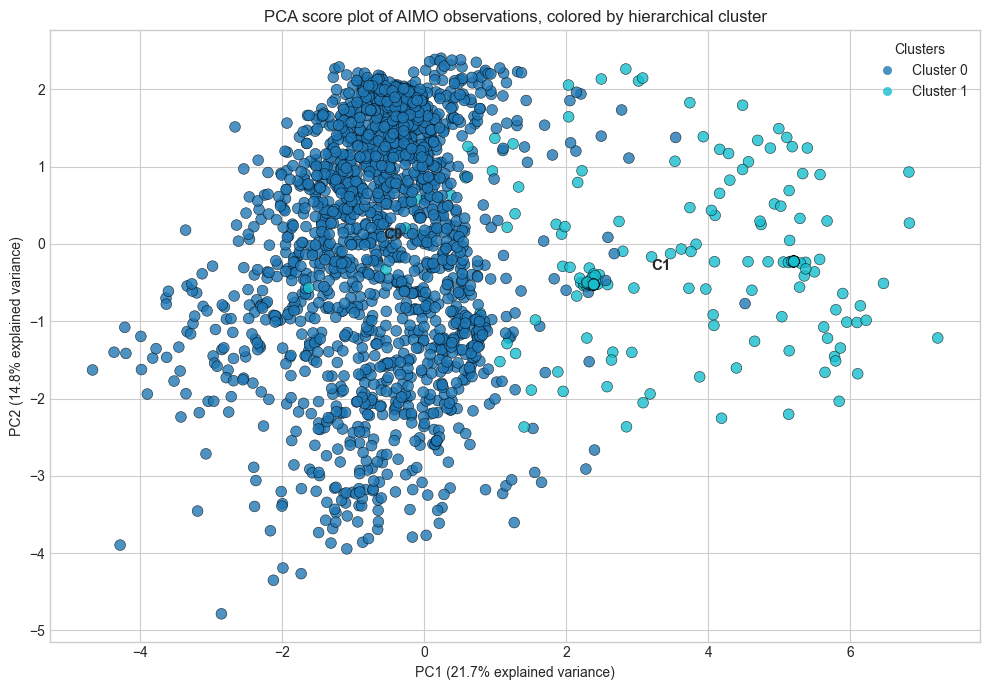

In [11]:
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["cluster"],
    cmap="tab10",
    s=60,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4,
)

centroids = pca_df.groupby("cluster")[["PC1", "PC2"]].mean()
for cluster_id, row in centroids.iterrows():
    ax.text(row["PC1"], row["PC2"], f"C{cluster_id}", fontsize=11, weight="bold")

legend_handles, _ = scatter.legend_elements()
legend_labels = [f"Cluster {cluster_id}" for cluster_id in sorted(pca_df["cluster"].unique())]
ax.legend(legend_handles, legend_labels, title="Clusters")

ax.set_title("PCA score plot of AIMO observations, colored by hierarchical cluster")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% explained variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% explained variance)")
plt.tight_layout()
plt.show()

In [12]:
def top_component_drivers(loadings: pd.DataFrame, component: str, top_n: int = 5) -> pd.Series:
    return loadings[component].reindex(loadings[component].abs().sort_values(ascending=False).head(top_n).index)


for component in ["PC1", "PC2"]:
    print(f"{component} explains {explained_variance[component] * 100:.2f}% of the variance")
    print(top_component_drivers(pca_loadings, component))
    print()

print("Cluster centroids in PCA space:")
centroids.round(3)

PC1 explains 21.68% of the variance
RightHeelRises           0.469815
RightKneeMovesOutward    0.456145
LeftHeelRises            0.332284
RightArmFallForward     -0.270187
ForwardHead             -0.268497
Name: PC1, dtype: float64

PC2 explains 14.77% of the variance
LeftArmFallForward             0.531008
RightArmFallForward            0.525310
RightShoulderElevation        -0.477062
LeftShoulderElevation         -0.317545
LeftAsymmetricalWeightShift   -0.182994
Name: PC2, dtype: float64

Cluster centroids in PCA space:


,PC1,PC2
cluster,,
0,-0.580,0.060
1,3.193,-0.333


## Interpretation of the results

The hierarchical clustering selected **2 clusters**, since this gave the highest silhouette score (**0.263**) among the tested values of `k`. That silhouette value is not very high, so the clustering should be interpreted as a **broad division of the observations** rather than two perfectly separated groups. Still, it is useful because it highlights one clearly distinct subgroup.

**Cluster 0** is the large main group with **1774 observations**. Its values are generally lower for `RightKneeMovesOutward`, `RightHeelRises`, and `LeftHeelRises`, which suggests that these observations show **less heel rise and less outward knee movement**, especially on the right side. Compared with Cluster 1, this group also has higher `ForwardHead`, `RightArmFallForward`, `ExcessiveForwardLean`, asymmetrical weight shift, and `RightKneeMovesInward`. A reasonable interpretation is that Cluster 0 represents the **more typical or general movement pattern** in the dataset.

**Cluster 1** is much smaller with **322 observations** and stands out clearly because it has much higher values for `RightKneeMovesOutward`, `RightHeelRises`, and `LeftHeelRises`. The z-score output shows that `RightKneeMovesOutward` is especially important for this cluster, with a much higher mean than the dataset average. At the same time, this cluster has lower `RightArmFallForward` and generally lower values for several trunk and weight-shift related variables. This suggests that Cluster 1 captures a **more specific movement pattern**, mainly characterized by **outward knee movement and heel rise**, especially on the right side.

The PCA helps visualize the same structure in two dimensions. The first two principal components explain about **36.4%** of the total variance together (`PC1 = 21.68%`, `PC2 = 14.77%`), so the plot does not represent the full dataset, but it still shows the main directions of variation. `PC1` is mainly driven by **positive loadings** for `RightHeelRises`, `RightKneeMovesOutward`, and `LeftHeelRises`, and **negative loadings** for `RightArmFallForward` and `ForwardHead`. This means that moving to the right along PC1 corresponds to observations with **more heel rise and outward knee movement**, while moving to the left corresponds more to **forward head and arm-fall-forward patterns**.

`PC2` is mainly driven by **positive loadings** for `LeftArmFallForward` and `RightArmFallForward`, and **negative loadings** for `RightShoulderElevation` and `LeftShoulderElevation`. So the vertical direction in the PCA plot mostly reflects a contrast between **arm-fall-forward variables** and **shoulder-elevation variables**.

In the PCA scatterplot, the two cluster centroids differ much more on **PC1** (`-0.580` vs `3.193`) than on **PC2** (`0.060` vs `-0.333`). This means the clusters are separated mainly **horizontally**, not vertically. That supports the interpretation that the most important distinction in the hierarchical clustering is the pattern of **heel rise and outward knee movement**, rather than the shoulder-related variation captured by PC2.

Overall, the hierarchical clustering suggests that the AIMO observations can be divided into:
- a **large general cluster** with lower heel-rise and outward-knee values
- a **smaller specialized cluster** with strong right-sided outward knee movement and heel rise

A good final conclusion for the report is that the clustering reveals a meaningful subgroup of observations with a distinct lower-body movement pattern, while the rest of the data forms a broader main cluster. The PCA plot supports this by showing that the main separation between clusters occurs along the component associated with **heel rise and outward knee movement**.